In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.special import erf

# Parameters
mu = 5.0      # drift
D = 0.4       # diffusion coefficiemunt
x0 = 4.3      # initial position
L = 5.0       # reflecting boundary at x = L
t = 0.1       # time
N = 100_000   # number of Monte Carlo samples

alpha: -5.0, beta: 0.4


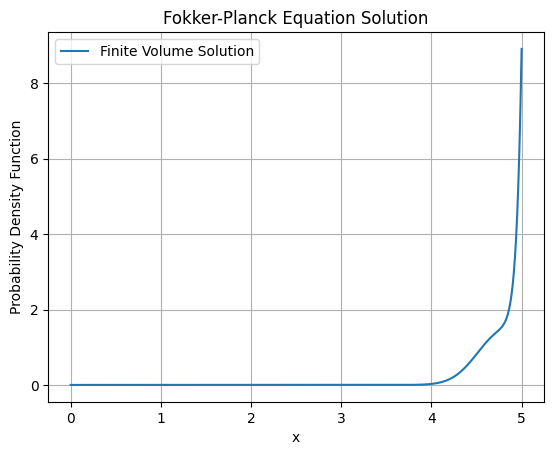

In [17]:
# Finite volume solution of fokker-planck equation

n = 401
x_grid = np.linspace(0, L, n)
dx = x_grid[1] - x_grid[0]

# Time-stepping parameters
dt = 0.001
num_steps = int(t / dt)
r1 = D * dt / dx**2
r2 = mu * dt / dx


pdf_fluid_ghost = np.zeros(n+2)
x_index = int(x0 / L * (n)) + 1
pdf_fluid_ghost[x_index] = 1/dx
# matrix A for implicit method
# assumes positive drift for upwind discretization
# and reflecting boundary at x = L and x = 0
alpha = - mu
beta = D

print(f"alpha: {alpha}, beta: {beta}")

A = np.zeros((n+2, n+2))
# A[0, 0] = r1
# A[0, 1] = - r1
# A[n-1, n-1] = r1 + 1.5 * r2
# A[n-1, n-2] = - r1 - 2 *r2
# A[n-1, n-3] = 0.5 * r2
A[0, 1] = -r1
A[0, 0] = r1
A[-1, -1] = alpha/2 + beta / dx
A[-1, -2] = alpha/2 - beta / dx
# A[-1, -2] = -1
# A[-1, -1] = 1
for i in range(1, n+1):
    if(i > 1):
        A[i, i] = 2 * r1 + 1.5 *r2
        A[i, i-1] = -r1 - 2 * r2
        A[i, i+1] = -r1
        A[i, i-2] = 0.5 * r2
    else:
        A[i, i] = 2 * r1 + r2
        A[i, i-1] = -r1 - r2
        A[i, i+1] = -r1


# backward Euler
A1 = np.eye(n+2) + A
A1[0, 0] -= 1
A1[-1, -1] -= 1

for step in range(num_steps):
    pdf_fluid_ghost = np.linalg.solve(A1, pdf_fluid_ghost)

# # heun
# A1 = np.eye(n+2)
# A1[0, 0] = 0
# A1[-1,-1] = 0
# A2 = A1

# A1 = A1 - 0.5 * A
# A1[-1, :] = 0
# A1[-1, -1] = 1
# A2 = A2 + 0.5 * A

# for step in range(num_steps):
#     pdf_fluid_ghost = np.linalg.solve(A2, A1 @ pdf_fluid_ghost)

pdf_fluid = pdf_fluid_ghost[1:-1]


# plot
plt.plot(x_grid, pdf_fluid, label='Finite Volume Solution')
plt.xlabel('x')
plt.ylabel('Probability Density Function')
plt.title('Fokker-Planck Equation Solution')
plt.legend()
plt.grid()
plt.show()

alpha: -4.3, beta: 0.4
A: 19674.498219336405
Area free: 0.7670796671392516, Area reflected: 1.2167143702685538e-05
Correct A: 19143.386365144856
test: 0.7602499389065234
A: 21706.17176320178
4.876791553802017
53.92850439281741
0.6011980757782922


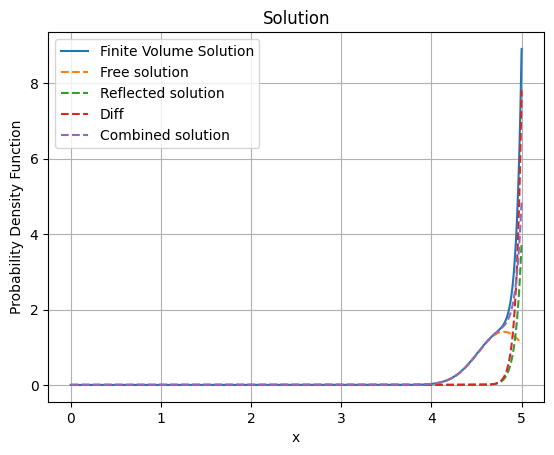

In [18]:
# Solution using method of images


density_moi = np.zeros(n)

density_moi = 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (x_grid - x0 - mu * t)**2 / (4 * D * t))

# source for the reflected image
x_image = 2 * L - x0 
# amplification factor

alpha = - mu + 0.7
beta = D

print(f"alpha: {alpha}, beta: {beta}")

A =  -(alpha - beta * (L - x0 - mu * t)/ (2 * D * t)) / (alpha - beta * (-L + x0 - mu * t)/ (2 * D * t)) * np.exp(2 * mu * (L - x0) / (2 * D))
print(f"A: {A}")

# Calculate A that would preserve the total density
density_reflected = 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (x_grid - x_image - mu * t)**2 / (4 * D * t))
area_free = np.sum(density_moi) * dx
area_reflected = np.sum(density_reflected) * dx

print(f"Area free: {area_free}, Area reflected: {area_reflected}")
print(f"Correct A: {(1 - area_free) / area_reflected}")

# A = (1 - area_free) / area_reflected

print(f"test: {0.5 * (1 + erf((L - x0 - mu * t) / (2 * np.sqrt(D * t))))}")

A = (1 - erf((L - x0 - mu * t) / (2 * np.sqrt(D * t)))) / (1 + erf((L - x_image - mu * t) / (2 * np.sqrt(D * t))))
print(f"A: {A}")

# value of combined solution at the boundary
val_boundary = 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (L - x0 - mu * t)**2 / (4 * D * t)) + A * 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (L - x_image - mu * t)**2 / (4 * D * t))
print(val_boundary)
der_boundary = -(L - x0 - mu * t)/(2*D*t) * 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (L - x0 - mu * t)**2 / (4 * D * t)) + A * (-(-L + x0 - mu * t))/(2*D*t) * 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (L - x_image - mu * t)**2 / (4 * D * t))
print(der_boundary)
# robin condition
print(alpha * val_boundary + beta * der_boundary)

# A = (L - x0 - mu * t) / (L - x0 + mu * t) * np.exp(2 * mu * (L - x0) / (2 * D))
# print(A)
density_reflected = A * 1. / np.sqrt(4 * np.pi * D * t) * np.exp(- (x_grid - x_image - mu * t)**2 / (4 * D * t))

plt.plot(x_grid, pdf_fluid, label='Finite Volume Solution')
plt.plot(x_grid, density_moi, label='Free solution', linestyle='--')
plt.plot(x_grid, density_reflected, label='Reflected solution', linestyle='--')
plt.plot(x_grid, pdf_fluid - density_moi, label='Diff', linestyle='--')
plt.plot(x_grid, density_moi + density_reflected, label='Combined solution', linestyle='--')
plt.xlabel('x')
plt.ylabel('Probability Density Function')
plt.title('Solution')
plt.legend()
plt.grid()
plt.show()


In [22]:
# Monte Carlo simulation of brownian motion
from scipy.stats import truncnorm

n_particles = 10000
dt = 0.0001

density_mc = np.zeros(n)

for i in range(n_particles):
    x = x0
    t_particle = 0
    while t_particle < t:
        x_new = x + mu * dt + np.sqrt(2 * D * dt) * np.random.normal()
        if x_new >= L:
            # Sample from the reflected image
            mean = 2 * L - x
            stddev = np.sqrt(2 * D * dt)
            x_new = truncnorm.rvs(-np.inf, (L - mean)/stddev, loc = (2 * L - x), scale = stddev)
        x = x_new
        t_particle += dt

    x_index = int(x / L * (n))
    density_mc[x_index] += 1 / (n_particles * dx)


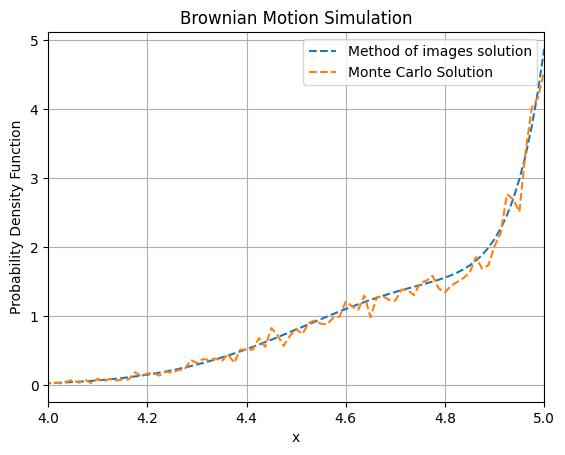

In [23]:
# plt.plot(x_grid, pdf_fluid, label='Finite Volume Solution')
plt.plot(x_grid, density_moi + density_reflected, label='Method of images solution', linestyle='--')
plt.plot(x_grid, density_mc, label='Monte Carlo Solution', linestyle='--')
plt.xlim(4, L)
plt.xlabel('x')
plt.ylabel('Probability Density Function')
plt.title('Brownian Motion Simulation')
plt.legend()
plt.grid()
plt.show()

In [24]:
# area under the curve

area = np.sum(pdf_fluid) * dx
print(f"Area under the finite volume curve: {area:.4f}")

area2 = np.sum(density_moi + density_reflected) * dx
print(f"Area under the analytical curve: {area2:.4f}")

area3 = np.sum(density_mc) * dx
print(f"Area under the Monte Carlo curve: {area3:.4f}")

Area under the finite volume curve: 1.2569
Area under the analytical curve: 1.0312
Area under the Monte Carlo curve: 1.0000
